# Problem Set 7 - Anomaly Detection


Submitted by: <b>Lanuzo, Jessica Mae T. | BSCS-2A </b>
***
Download a clustering dataset from UCI Machine Learning Repository. Then explore the dataset using the code implementation explained in the link below:
https://medium.com/@amir.yavariabdi/anomaly-detection-in-python-with-gaussian-distribution-and-k-means-clustering-89d09d16fba4

Write a report containing two (2) sections describing the Dataset and the Result. Submit the report file named as PS7_LastName_Section.pdf and a zip file named as PS7_LastName_Section.zip containing your code and the dataset. Lastly, submit a similarity rating by following this instruction: https://medium.com/@renatoivadriano/turnitin-draft-coach-cspc-institutional-support-walkthrough-54a3e9629fa9. Allowable similarity score is below 20%.

     The Dataset: Online Shoppers Purchasing Intention Dataset


> Of the 12,330 sessions in the dataset, 84.5% (10,422) were negative class samples that did not end with shopping, and the rest (1908) were positive class samples ending with shopping.

> Repository URL: https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset

***
### Anomaly Detection on Online Shoppers Purchasing Intention Dataset


#### Import Libraries

In [221]:
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import multivariate_normal
%matplotlib inline
import plotly.graph_objs as go
from plotly.offline import download_plotlyjs,init_notebook_mode,plot,iplot
init_notebook_mode(connected=True)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import plotly.graph_objects as go
from scipy.stats import norm

#### Load and Prepare the Dataset

In [222]:
train_df = pd.read_csv("online_shoppers_intention.csv")
print(train_df.columns.values)

['Administrative' 'Administrative_Duration' 'Informational'
 'Informational_Duration' 'ProductRelated' 'ProductRelated_Duration'
 'BounceRates' 'ExitRates' 'PageValues' 'SpecialDay' 'Month'
 'OperatingSystems' 'Browser' 'Region' 'TrafficType' 'VisitorType'
 'Weekend' 'Revenue']


In [223]:
#Fill the empty cells with NAN and then drop them.
for (columnName, columnData) in train_df.items():
    train_df[columnName].replace('', np.nan, inplace=True)
train_df = train_df.dropna(subset=train_df.columns.values)
train_df.head(5)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


#### Test for a normal distribution

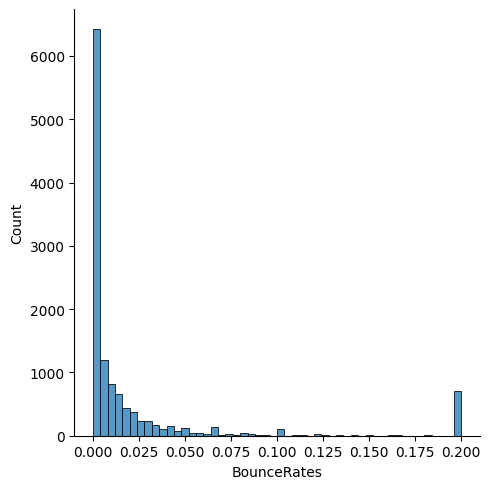

In [224]:
feature_name = train_df.iloc[:,6:7].columns
plt.figure
for i, cn in enumerate(train_df[feature_name]):
    sns.displot(train_df[cn], bins=50)
plt.show()

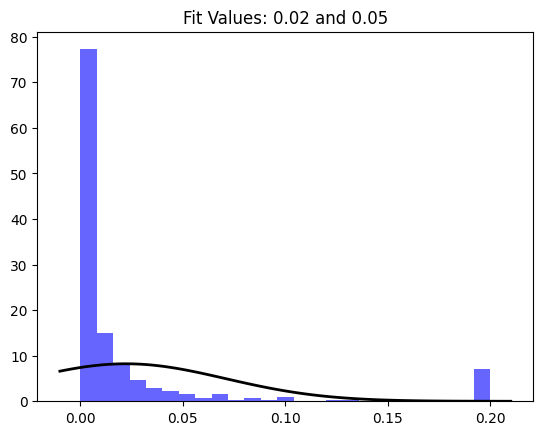

In [225]:
mu, std = norm.fit(train_df[feature_name]) 
  
# Plot the histogram.
plt.hist(train_df[feature_name], bins=25, density=True, alpha=0.6, color='b')
  
# Plot the PDF.
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
  
plt.plot(x, p, 'k', linewidth=2)
title = "Fit Values: {:.2f} and {:.2f}".format(mu, std)
plt.title(title)
  
plt.show()

#### Model data with Gaussian (normal) distribution

In [226]:
# step 1:
def estimateGaussian(x):
    mu = np.mean(x, axis=0)
    sigma = np.cov(x.T)
    print(mu)
    print(sigma)
    return mu, sigma

# steps 2 and 3:
def multivariateGaussian(x,mu,sigma):
    g = multivariate_normal(mean=mu, cov=sigma)
    return g.pdf(x)

In [227]:
X=train_df.iloc[:,6:7]
X.to_numpy()
mu, sigma = estimateGaussian(X)
p = multivariateGaussian(X,mu,sigma)

BounceRates    0.022191
dtype: float64
0.002351117351587493


### Anomaly detection using empirically-set threshold

In [228]:
# print minimum and maximum of probabilities (p)
print("min: {0}".format(min(p)))
print("max: {0}".format(max(p)))

# print the first 10 minimum values from p
idx=np.argpartition(p,10)
a=p[idx[:10]]
a.sort()
print("First 10 min: {0}".format(a))

# print the mean and variance of p
v=np.var(p)
m=sum(p) / len(p)
print("var: {0}".format(v))
print("mean: {0}".format(m))

min: 0.009891319606336412
max: 8.22759346662273
First 10 min: [0.00989132 0.00989132 0.00989132 0.00989132 0.00989132 0.00989132
 0.00989132 0.00989132 0.00989132 0.00989132]
var: 3.916843169195668
mean: 7.027017047604363


In [229]:
predictions = (p <  2*v)
anomalyg=X[predictions==True]
anomaly_indexg=list(anomalyg.index)
anomalyg.to_numpy()

array([[0.2       ],
       [0.        ],
       [0.2       ],
       ...,
       [0.08333333],
       [0.        ],
       [0.        ]])

##### Plot anomalies in the dataset based on the selected T:

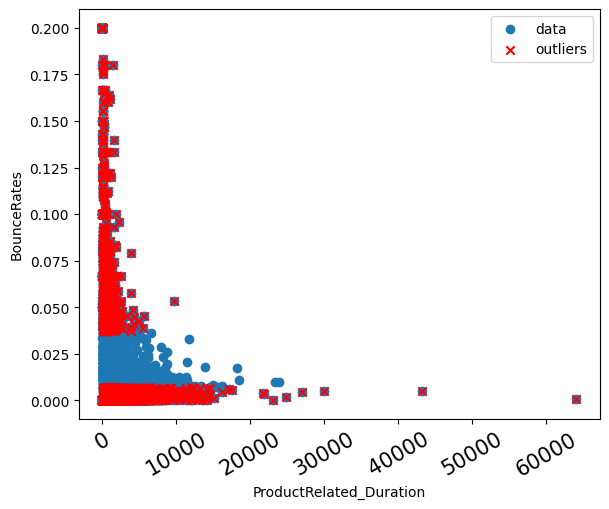

In [230]:
# Anomalies in dataset
# x-axis: ProductRelated_Duration   y-axis: BounceRates 
X1 = list(train_df.iloc[:,5]) 
Y = list(train_df.iloc[:,6])

# find outlier Duration in Product-related pages
tt=train_df.iloc[:,5]
tt.to_numpy()
anomalygx=tt[predictions==True]

# x-axis: ProductRelated_Duration of Outliers  y-axis: outliers in BounceRates
Xano=list(anomalygx)
Yano=anomalyg
fig=plt.figure(figsize=(6,5))

# plot BounceRates and its outliers
plot=plt.scatter(X1, Y,label="data")
plot=plt.scatter(Xano,Yano, marker='x', color='red',label="outliers")

# Setting Ticks
plt.tick_params(axis='x',labelsize=15,rotation=30)
plt.tight_layout()
plt.xlabel("ProductRelated_Duration")
plt.ylabel("BounceRates")
plt.legend()
# Display
plt.show()

##### Plot anomalies among probabilities:

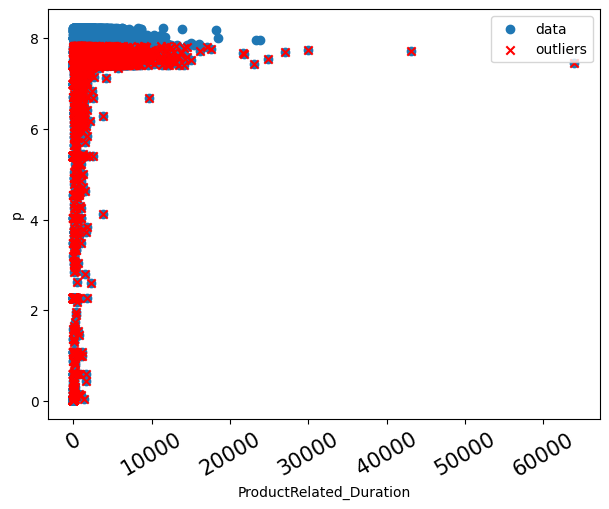

In [231]:
# x-axis: ProductRelated_Duration   y-axis: BounceRates
X1 = list(train_df.iloc[:,5])
Yp = list(p)

# find outlier Duration in Product-related pages
tt=train_df.iloc[:,5]
tt.to_numpy()
anomalygx=tt[predictions==True]

# x-axis: ProductRelated_Duration of Outliers  y-axis: outliers in p
Xano=list(anomalygx)
Ypano=p[predictions==True]
fig=plt.figure(figsize=(6,5))
plot=plt.scatter(X1, Yp,label="data")
plot=plt.scatter(Xano,Ypano, marker='x', color='red',label="outliers")
plt.tick_params(axis='x',labelsize=15,rotation=30)
plt.tight_layout()
plt.xlabel("ProductRelated_Duration")
plt.ylabel("p")
plt.legend()
plt.show()

### Automatically-set threshold using K-means

In [232]:
sil = []
kmax = 150

for k in range(2, kmax+1):
  kmeans = KMeans(n_clusters = k).fit(p.reshape(-1,1))
  labels = kmeans.labels_
  sil.append(silhouette_score(p.reshape(-1,1), labels, metric = 'euclidean'))

In [233]:
mean_score=float('%.2f' % (sum(sil) / len(sil)))
fig = go.Figure()
fig.add_trace(go.Scatter(name="score",x=list(range(2,151)), y=list(sil)))
fig.add_trace(go.Scatter(name="mean",x=list(range(2,151)), y=list(np.ones(k-1)*[mean_score])))

In [234]:
def closest_node(node, nodes):
    nodes = np.asarray(nodes)
    dist_2 = np.sum((nodes - node)**2, axis=1)
    return np.argmin(dist_2)

k_cluster=closest_node(mean_score, np.array(sil).reshape(-1,1))
k_cluster

np.int64(69)

### K-means Clustering:


In [235]:
kmeans = KMeans(n_clusters=k_cluster, random_state=0).fit(p.reshape(-1,1))


In [236]:
# Generate random colormap
def rand_cmap(nlabels, type='bright', first_color_black=True, last_color_black=False, verbose=True):

    from matplotlib.colors import LinearSegmentedColormap
    import colorsys
    import numpy as np
    import sys


    if type not in ('bright', 'soft'):
        print ('Please choose "bright" or "soft" for type')
        return

    if verbose:
        print('Number of labels: ' + str(nlabels))

    # Generate color map for bright colors, based on hsv
    if type == 'bright':
        randHSVcolors = [(np.random.uniform(low=0.0, high=1),
                          np.random.uniform(low=0.2, high=1),
                          np.random.uniform(low=0.9, high=1)) for i in list(range(nlabels))]

        # Convert HSV list to RGB
        randRGBcolors = []
        for HSVcolor in randHSVcolors:
            randRGBcolors.append(colorsys.hsv_to_rgb(HSVcolor[0], HSVcolor[1], HSVcolor[2]))

        if first_color_black:
            randRGBcolors[0] = [0, 0, 0]

        if last_color_black:
            randRGBcolors[-1] = [0, 0, 0]

        random_colormap = LinearSegmentedColormap.from_list('new_map', randRGBcolors, N=nlabels)

    # Generate soft pastel colors, by limiting the RGB spectrum
    if type == 'soft':
        low = 0.6
        high = 0.95
        randRGBcolors = [(np.random.uniform(low=low, high=high),
                          np.random.uniform(low=low, high=high),
                          np.random.uniform(low=low, high=high)) for i in xrange(nlabels)]

        if first_color_black:
            randRGBcolors[0] = [0, 0, 0]

        if last_color_black:
            randRGBcolors[-1] = [0, 0, 0]
        random_colormap = LinearSegmentedColormap.from_list('new_map', randRGBcolors, N=nlabels)

    # Display colorbar
    if verbose:
        from matplotlib import colors, colorbar
        from matplotlib import pyplot as plt
        fig, ax = plt.subplots(1, 1, figsize=(15, 0.5))

        bounds = np.linspace(0, nlabels, nlabels + 1)
        norm = colors.BoundaryNorm(bounds, nlabels)

        cb = colorbar.ColorbarBase(ax, cmap=random_colormap, norm=norm, spacing='proportional', ticks=None,
                                   boundaries=bounds, format='%1i', orientation=u'horizontal')
 
    return random_colormap

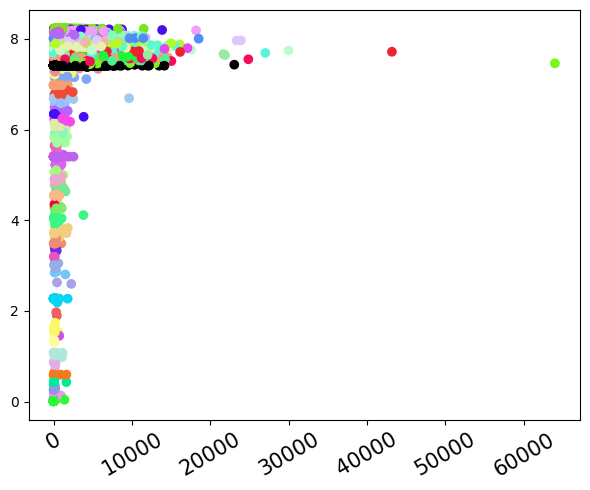

In [237]:
new_cmap = rand_cmap(k_cluster, type='bright', first_color_black=True, last_color_black=False, verbose=False)
fig=plt.figure(figsize=(6,5))
plt.scatter(X1, Yp, c=kmeans.labels_, cmap=new_cmap, vmin=0, vmax=k_cluster)
plt.tick_params(axis='x',labelsize=15,rotation=30)
plt.tight_layout()
plt.show()

In [238]:
centroids = kmeans.cluster_centers_
centroids.T.sort() 
print((centroids[0:2]))

[[0.01026964]
 [0.13384709]]


In [239]:
predictions1 = (p <=  centroids[0])
anomalygserious=X[predictions1==True]
anomaly_indexg=list(anomalyg.index)
anomalyg.to_numpy()

array([[0.2       ],
       [0.        ],
       [0.2       ],
       ...,
       [0.08333333],
       [0.        ],
       [0.        ]])

In [240]:
predictions2 = ((p<= centroids[1] ) & (p>centroids[0]))
anomalyg=X[predictions2==True]
anomaly_indexg=list(anomalyg.index)
anomalyg.to_numpy()

array([[0.16190476],
       [0.16428571],
       [0.18333333],
       [0.16666667],
       [0.17692308],
       [0.18      ],
       [0.18      ],
       [0.18      ],
       [0.18      ],
       [0.16423077],
       [0.16666667],
       [0.18      ],
       [0.16666667],
       [0.175     ],
       [0.16666667]])

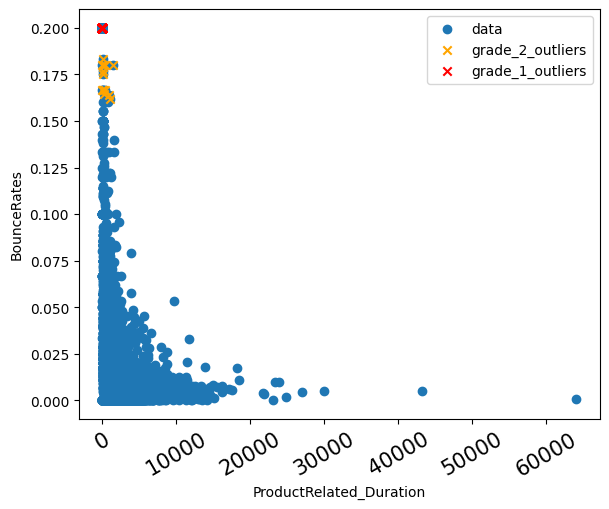

In [244]:
X1 = list(train_df.iloc[:,5])
Y = list(train_df.iloc[:,6])
tt=train_df.iloc[:,5]
tt = tt.to_numpy()
anomalygx=tt[predictions1==True]
Xanoserious=list(anomalygx)
Yanoserious=anomalygserious
anomalygx=tt[predictions2==True]
Xano=list(anomalygx)
Yano=anomalyg
fig=plt.figure(figsize=(6,5))

# Plotly graph
plot=plt.scatter(X1, Y,label="data")
plot=plt.scatter(Xano,Yano, marker='x', color='orange',label="grade_2_outliers")
plot=plt.scatter(Xanoserious,Yanoserious, marker='x', color='red',label="grade_1_outliers")

# Setting Ticks
plt.tick_params(axis='x',labelsize=15,rotation=30)
plt.tight_layout()
plt.xlabel("ProductRelated_Duration")
plt.ylabel("BounceRates")
plt.legend()
# Display
plt.show()

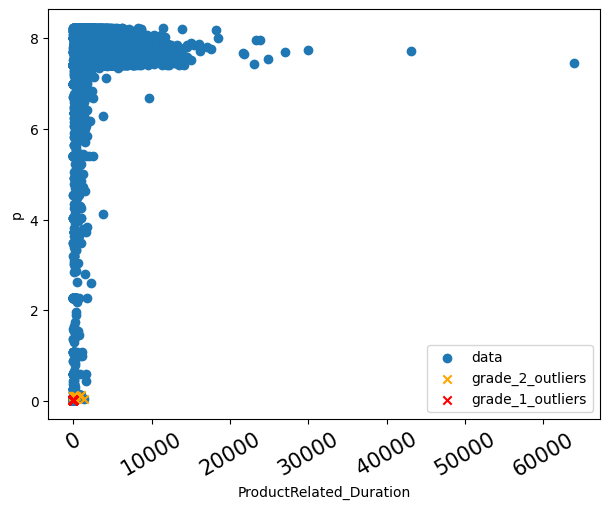

In [245]:
X1 = list(train_df.iloc[:,5])
Yp = list(p)
tt=train_df.iloc[:,5]
tt = tt.to_numpy()
anomalygx=tt[predictions1==True]
Xanoserious=list(anomalygx)
Ypanoserious=p[predictions1==True]
anomalygx=tt[predictions2==True]
Xano=list(anomalygx)
Ypano=p[predictions2==True]
fig=plt.figure(figsize=(6,5))

# Plotly graph
plot=plt.scatter(X1, Yp,label="data")
plot=plt.scatter(Xano,Ypano, marker='x', color='orange',label="grade_2_outliers")
plot=plt.scatter(Xanoserious,Ypanoserious, marker='x', color='red',label="grade_1_outliers")

# Setting Ticks
plt.tick_params(axis='x',labelsize=15,rotation=30)
plt.tight_layout()
plt.xlabel("ProductRelated_Duration")
plt.ylabel("p")
plt.legend()
# Display
plt.show()

####